<center><h1>Magdum_Seona_HW8</h1></center>

Name: Seona Magdum
<br>
Github Username: seo2003
<br>
USC ID: 6077378254

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [106]:
from IPython.display import display, HTML

display(HTML("""
<style>
.cm-editor {
    font-size: 11px !important;
}
.jp-OutputArea pre {
    font-size: 11px !important;
}
</style>
"""))

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.neighbors import KNeighborsClassifier

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [105]:
columns = ['ID', 'Diagnosis'] + [f'Feature_{i}' for i in range(1, 31)]

df = pd.read_csv('../data/wdbc.data', header=None, names=columns)
print(df.shape)
df.head()

(569, 32)


,ID,Diagnosis,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,...,Feature_21,Feature_22,Feature_23,Feature_24,Feature_25,Feature_26,Feature_27,Feature_28,Feature_29,Feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

In [76]:
X = df.drop(columns=['ID', 'Diagnosis'])
y = (df['Diagnosis'] == 'M').astype(int)

print(X.shape)
print(y.value_counts())

(569, 30)
Diagnosis
0    357
1    212
Name: count, dtype: int64


In [77]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000, tol=1e-4))
])
param_grid = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]}
cv = StratifiedKFold(n_splits=5, shuffle=True)

In [78]:
M = 30
results = []
run1 = None
for run in range(M):
    #split each class separately
    X_train_list, X_test_list = [], []
    y_train_list, y_test_list = [], []
    for cls in [0, 1]:
        idx = np.where(y == cls)[0]
        train_idx, test_idx = train_test_split(
            idx, test_size=0.2, random_state=run
        )
        X_train_list.append(X.iloc[train_idx])
        X_test_list.append(X.iloc[test_idx])
        y_train_list.append(y.iloc[train_idx])
        y_test_list.append(y.iloc[test_idx])
    X_train = pd.concat(X_train_list)
    X_test = pd.concat(X_test_list)
    y_train = pd.concat(y_train_list)
    y_test = pd.concat(y_test_list)
    #5 fold
    grid = GridSearchCV(
        pipeline, param_grid, cv=cv, scoring='accuracy', n_jobs=-1
    )
    grid.fit(X_train, y_train)
    model = grid.best_estimator_
    #predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_score = model.decision_function(X_train)
    test_score = model.decision_function(X_test)
    #calculate
    for split, yt, yp, score in [
        ('Train', y_train, y_train_pred, train_score),
        ('Test', y_test, y_test_pred, test_score)
    ]:
        results.append({
            'Run': run + 1,
            'Set': split,
            'C': grid.best_params_['svm__C'],
            'Accuracy': accuracy_score(yt, yp),
            'Precision': precision_score(yt, yp),
            'Recall': recall_score(yt, yp),
            'F1': f1_score(yt, yp),
            'AUC': roc_auc_score(yt, score)
        })
    #save first run for ROC and confusion matrices
    if run == 0:
        run1 = (y_train, y_train_pred, train_score,
                y_test, y_test_pred, test_score)

results_df = pd.DataFrame(results)

In [79]:
avg_scores = results_df.groupby('Set')[[
    'Accuracy', 'Precision', 'Recall', 'F1', 'AUC'
]].mean()
print(avg_scores.round(4))
print(results_df[results_df['Set'] == 'Test']['C'].value_counts())

       Accuracy  Precision  Recall      F1     AUC
Set                                               
Test     0.9739     0.9791  0.9512  0.9643  0.9939
Train    0.9841     0.9891  0.9679  0.9784  0.9968
C
0.10    26
0.01     2
1.00     2
Name: count, dtype: int64


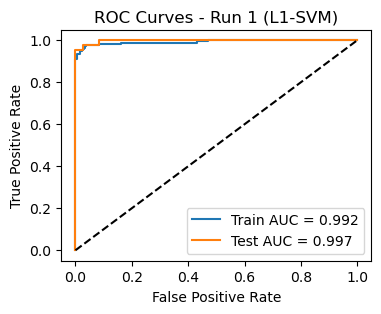

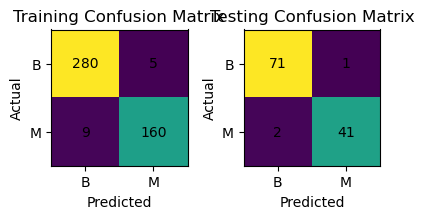

In [80]:
y_train, y_train_pred, train_score, y_test, y_test_pred, test_score = run1
#ROC curves
fpr_train, tpr_train, _ = roc_curve(y_train, train_score)
fpr_test, tpr_test, _ = roc_curve(y_test, test_score)
plt.figure(figsize=(4, 3))
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {roc_auc_score(y_train, train_score):.3f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {roc_auc_score(y_test, test_score):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Run 1 (L1-SVM)')
plt.legend()
plt.show()
#confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(4, 3))
for ax, yt, yp, title in [
    (axes[0], y_train, y_train_pred, 'Training Confusion Matrix'),
    (axes[1], y_test, y_test_pred, 'Testing Confusion Matrix')
]:
    cm = confusion_matrix(yt, yp)
    ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0, 1], ['B', 'M'])
    ax.set_yticks([0, 1], ['B', 'M'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout()
plt.show()

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [81]:
M = 30
semi_A_results = []
semi_runs = []
param_grid = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100]}
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000))
])
for run in range(M):
    #split 20% of each class for testing
    X_train_list, X_test_list = [], []
    y_train_list, y_test_list = [], []
    for cls in [0, 1]:
        idx = np.where(y == cls)[0]
        train_idx, test_idx = train_test_split(
            idx, test_size=0.2, random_state=run
        )
        X_train_list.append(X.iloc[train_idx])
        X_test_list.append(X.iloc[test_idx])
        y_train_list.append(y.iloc[train_idx])
        y_test_list.append(y.iloc[test_idx])

    X_train = pd.concat(X_train_list).reset_index(drop=True)
    X_test = pd.concat(X_test_list).reset_index(drop=True)
    y_train = pd.concat(y_train_list).reset_index(drop=True)
    y_test = pd.concat(y_test_list).reset_index(drop=True)

    #randomly select 50% of each class as labeled
    rng = np.random.RandomState(run)
    labeled_idx, unlabeled_idx = [], []

    for cls in [0, 1]:
        idx = np.where(y_train == cls)[0]
        rng.shuffle(idx)
        n_labeled = int(len(idx) * 0.5)
        labeled_idx.extend(idx[:n_labeled])
        unlabeled_idx.extend(idx[n_labeled:])

    labeled_idx = np.array(labeled_idx)
    unlabeled_idx = np.array(unlabeled_idx)

    X_labeled = X_train.iloc[labeled_idx]
    y_labeled = y_train.iloc[labeled_idx]

    #5 fold cv
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run)

    grid = GridSearchCV(
        pipeline, param_grid, cv=cv, scoring='accuracy', n_jobs=-1
    )
    grid.fit(X_labeled, y_labeled)
    model = grid.best_estimator_
    best_C = grid.best_params_['svm__C']
    for split, Xt, yt in [
        ('Labeled Train', X_labeled, y_labeled),
        ('Test', X_test, y_test)
    ]:
        yp = model.predict(Xt)
        score = model.decision_function(Xt)
        semi_A_results.append({
            'Run': run + 1,
            'Set': split,
            'C': best_C,
            'Accuracy': accuracy_score(yt, yp),
            'Precision': precision_score(yt, yp),
            'Recall': recall_score(yt, yp),
            'F1': f1_score(yt, yp),
            'AUC': roc_auc_score(yt, score)
        })

    #saving data 
    semi_runs.append({
        'X_train': X_train,
        'y_train': y_train,
        'X_test': X_test,
        'y_test': y_test,
        'labeled_idx': labeled_idx,
        'unlabeled_idx': unlabeled_idx,
        'X_labeled': X_labeled,
        'y_labeled': y_labeled,
        'C': best_C,
        'model': model
    })

In [82]:
semi_A_df = pd.DataFrame(semi_A_results)
print(semi_A_df.groupby('Set')[[
    'Accuracy', 'Precision', 'Recall', 'F1', 'AUC'
]].mean().round(4))

               Accuracy  Precision  Recall      F1     AUC
Set                                                       
Labeled Train    0.9847     0.9916  0.9671  0.9791  0.9969
Test             0.9696     0.9696  0.9496  0.9590  0.9921


##### (B)

In [83]:
semi_B_results = []
semi_run1_B = None
for run in range(M):
    data = semi_runs[run]
    X_train = data['X_train']
    y_train = data['y_train']
    X_test = data['X_test']
    y_test = data['y_test']
    labeled_idx = data['labeled_idx'].copy()
    unlabeled_idx = data['unlabeled_idx'].copy()
    C = data['C']
    X_labeled = X_train.iloc[labeled_idx].copy()
    y_labeled = y_train.iloc[labeled_idx].copy().reset_index(drop=True)

    # use C from part a
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', LinearSVC(
            penalty='l1', dual=False, C=C, max_iter=100000
        ))
    ])
    model = pipeline.fit(X_labeled, y_labeled)
    #add the farthest unlabeled observation
    while len(unlabeled_idx) > 0:
        scores = model.decision_function(X_train.iloc[unlabeled_idx])
        #select the point farthest from the decision boundary
        farthest_pos = np.argmax(np.abs(scores))
        selected_idx = unlabeled_idx[farthest_pos]
        pseudo_label = model.predict(X_train.iloc[[selected_idx]])[0]
        #add selected observation and pseudo-label
        X_labeled = pd.concat([
            X_labeled, X_train.iloc[[selected_idx]]
        ], ignore_index=True)
        y_labeled = pd.concat([
            y_labeled, pd.Series([pseudo_label])
        ], ignore_index=True)
        #train
        model = pipeline.fit(X_labeled, y_labeled)
        #remove selected observation from unlabeled set
        unlabeled_idx = np.delete(unlabeled_idx, farthest_pos)
    #final predictions 
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_score = model.decision_function(X_train)
    test_score = model.decision_function(X_test)
    for split, yt, yp, score in [
        ('Train', y_train, y_train_pred, train_score),
        ('Test', y_test, y_test_pred, test_score)
    ]:
        semi_B_results.append({
            'Run': run + 1,
            'Set': split,
            'C': C,
            'Accuracy': accuracy_score(yt, yp),
            'Precision': precision_score(yt, yp),
            'Recall': recall_score(yt, yp),
            'F1': f1_score(yt, yp),
            'AUC': roc_auc_score(yt, score)
        })
    #saving run 1 
    if run == 0:
        semi_run1_B = (
            y_train, y_train_pred, train_score,
            y_test, y_test_pred, test_score
        )


In [84]:
semi_B_df = pd.DataFrame(semi_B_results)
semi_B_avg = semi_B_df.groupby('Set')[[
    'Accuracy', 'Precision', 'Recall', 'F1', 'AUC'
]].mean()

print(semi_B_avg.round(4))

       Accuracy  Precision  Recall      F1     AUC
Set                                               
Test     0.9664     0.9737  0.9364  0.9542  0.9915
Train    0.9737     0.9832  0.9458  0.9640  0.9941


In [85]:
print(semi_B_df[semi_B_df['Set'] == 'Test']['C'].value_counts())

C
0.10      21
1.00       7
0.01       1
100.00     1
Name: count, dtype: int64


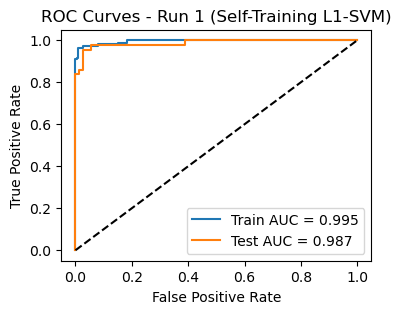

In [86]:
y_train, y_train_pred, train_score, y_test, y_test_pred, test_score = semi_run1_B
fpr_train, tpr_train, _ = roc_curve(y_train, train_score)
fpr_test, tpr_test, _ = roc_curve(y_test, test_score)
plt.figure(figsize=(4, 3))
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {roc_auc_score(y_train, train_score):.3f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {roc_auc_score(y_test, test_score):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Run 1 (Self-Training L1-SVM)')
plt.legend()
plt.show()

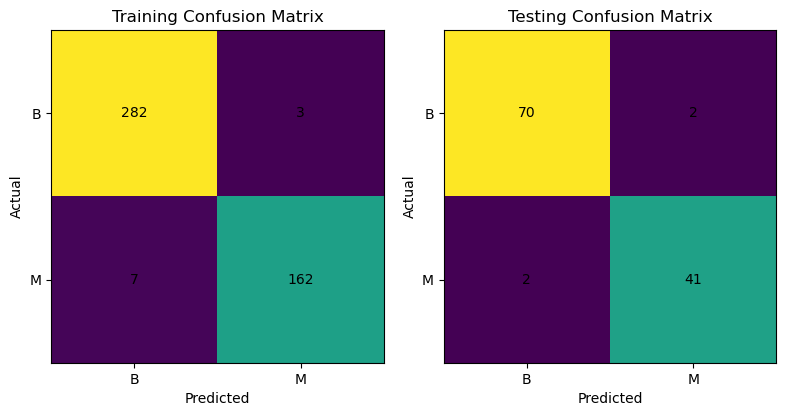

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, yt, yp, title in [
    (axes[0], y_train, y_train_pred, 'Training Confusion Matrix'),
    (axes[1], y_test, y_test_pred, 'Testing Confusion Matrix')
]:
    cm = confusion_matrix(yt, yp)
    ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0, 1], ['B', 'M'])
    ax.set_yticks([0, 1], ['B', 'M'])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

#### (iii) Unsupervised Learning

##### (A)

In [88]:
M = 30
kmeans_results = []
for run in range(M):
    X_train = semi_runs[run]['X_train']
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)
    kmeans = KMeans(n_clusters=2, init='random', n_init=50, random_state=run)
    clusters = kmeans.fit_predict(X_scaled)
    kmeans_results.append({
        'Run': run + 1,
        'Inertia': kmeans.inertia_,
        'Clusters': clusters,
        'Model': kmeans,
        'Scaler': scaler
    })
inertia_values = [result['Inertia'] for result in kmeans_results]
print('Average inertia:', np.mean(inertia_values))
print('Minimum inertia:', np.min(inertia_values))
print('Maximum inertia:', np.max(inertia_values))


Average inertia: 9259.779389167052
Minimum inertia: 9016.11964661059
Maximum inertia: 9386.877061398674


K-means was initialized randomly and run 50 times using different initial centroid positions for each Monte Carlo repetition. To make sure the algorithm was not trapped in a poor local minimum, I used multiple random initializations, since K-means can converge to different clustering solutions. The solution with the lowest within-cluster sum of squared distances among the 50 initializations was selected. The average inertia across Monte Carlo repetitions was 9,259.78, with a minimum of 9,016.12 and a maximum of 9,386.88. The small variation in inertia suggests that the clustering results were consistent across Monte Carlo repetitions.

##### (B)

Average K-means Performance over 30 Runs:
Accuracy     0.9088
Precision    0.9207
Recall       0.8266
F1           0.8709
AUC          0.8921
dtype: float64


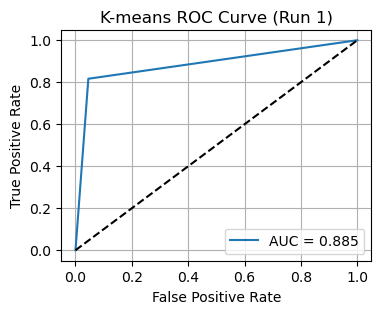

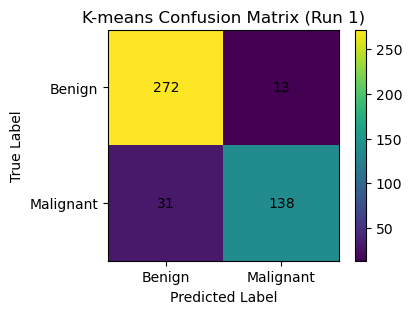

In [89]:
M = 30
kmeans_eval_results = []
kmeans_run1 = None
for run in range(M):
    X_train = semi_runs[run]['X_train']
    y_train = semi_runs[run]['y_train']
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train)
    #k means with multiple random initializations to avoid local minima
    model = KMeans(n_clusters=2, init='random', n_init=50, random_state=run)
    clusters = model.fit_predict(X_scaled)
    #assign a true label to each cluster using the closest 30 points
    cluster_labels = {}
    for cluster in range(2):
        distances = np.linalg.norm(X_scaled - model.cluster_centers_[cluster], axis=1)
        closest_idx = np.argsort(distances)[:30]
        cluster_labels[cluster] = y_train.iloc[closest_idx].mode()[0]
    #assign cluster majority labels to all training observations
    y_pred = np.array([cluster_labels[c] for c in clusters])
    y_score = y_pred
    #evaluate performance
    kmeans_eval_results.append({
        'Run': run + 1,
        'Accuracy': accuracy_score(y_train, y_pred),
        'Precision': precision_score(y_train, y_pred),
        'Recall': recall_score(y_train, y_pred),
        'F1': f1_score(y_train, y_pred),
        'AUC': roc_auc_score(y_train, y_score)
    })

    #save Run 1 
    if run == 0:
        kmeans_run1 = (y_train, y_pred, y_score, clusters, cluster_labels)
#average metrics across 30 runs
kmeans_eval_df = pd.DataFrame(kmeans_eval_results)
kmeans_avg_scores = kmeans_eval_df[['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']].mean()
print("Average K-means Performance over 30 Runs:")
print(kmeans_avg_scores.round(4))
#roc curve for Run 1
y_train, y_pred, y_score, clusters, cluster_labels = kmeans_run1
fpr, tpr, _ = roc_curve(y_train, y_score)
plt.figure(figsize=(4, 3))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_train, y_score):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('K-means ROC Curve (Run 1)')
plt.legend()
plt.grid()
plt.show()
#confusion matrix for Run 1
cm = confusion_matrix(y_train, y_pred)
plt.figure(figsize=(4, 3))
plt.imshow(cm)
plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('K-means Confusion Matrix (Run 1)')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

##### (C)

Average K-means Test Performance over 30 Runs:
Accuracy     0.9119
Precision    0.9240
Recall       0.8333
F1           0.8757
AUC          0.8961
dtype: float64


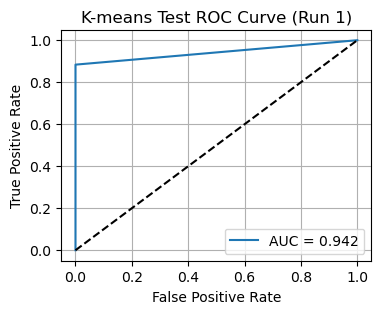

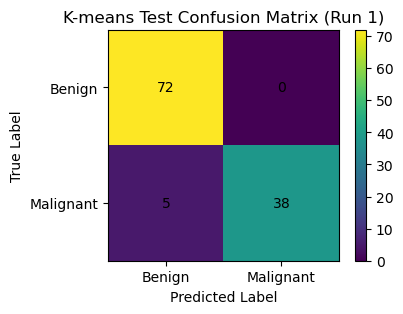

In [90]:
kmeans_test_results = []
kmeans_test_run1 = None
for run in range(M):
    X_train = semi_runs[run]['X_train']
    y_train = semi_runs[run]['y_train']
    X_test = semi_runs[run]['X_test']
    y_test = semi_runs[run]['y_test']
    model = kmeans_results[run]['Model']
    scaler = kmeans_results[run]['Scaler']
    X_test_scaled = scaler.transform(X_test)
    #assign test observations to the nearest cluster center
    test_clusters = model.predict(X_test_scaled)
    #predict test labels using the majority-vote label of each cluster
    cluster_labels = kmeans_eval_results[run]['Cluster_Labels'] if 'Cluster_Labels' in kmeans_eval_results[run] else None

    if cluster_labels is None:
        cluster_labels = {}
        X_train_scaled = scaler.transform(X_train)
        clusters = kmeans_results[run]['Clusters']

        for cluster in range(2):
            distances = np.linalg.norm(X_train_scaled - model.cluster_centers_[cluster], axis=1)
            closest_idx = np.argsort(distances)[:30]
            cluster_labels[cluster] = y_train.iloc[closest_idx].mode()[0]
    y_test_pred = np.array([cluster_labels[c] for c in test_clusters])
    y_test_score = y_test_pred
    #evaluate test performance
    kmeans_test_results.append({
        'Run': run + 1,
        'Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred, zero_division=0),
        'Recall': recall_score(y_test, y_test_pred, zero_division=0),
        'F1': f1_score(y_test, y_test_pred, zero_division=0),
        'AUC': roc_auc_score(y_test, y_test_score)
    })

    if run == 0:
        kmeans_test_run1 = (y_test, y_test_pred, y_test_score)

#average test metrics across 30 runs
kmeans_test_df = pd.DataFrame(kmeans_test_results)
kmeans_test_avg = kmeans_test_df[['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']].mean()

print("Average K-means Test Performance over 30 Runs:")
print(kmeans_test_avg.round(4))

#rOC curve for Run 1 (test data)
y_test, y_test_pred, y_test_score = kmeans_test_run1

fpr, tpr, _ = roc_curve(y_test, y_test_score)
plt.figure(figsize=(4, 3))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_test_score):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('K-means Test ROC Curve (Run 1)')
plt.legend()
plt.grid()
plt.show()

#confusion matrix for Run 1 (test data)
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(4, 3))
plt.imshow(cm)
plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('K-means Test Confusion Matrix (Run 1)')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

#### (iv) Spectral Clustering

Spectral clustering is clustering method that uses the similarities between data points to identify clusters. K-means groups data points based on how close they are to cluster centers, while spectral clustering groups points based on how similar and connected they are to each other. Spectral clustering uses the connections between data points to find groups, even when the clusters have irregular shapes that K-means may struggle to identify.

Average Spectral Clustering Test Performance:
Accuracy     0.6287
Precision    0.3000
Recall       0.0070
F1           0.0136
AUC          0.5035
dtype: float64


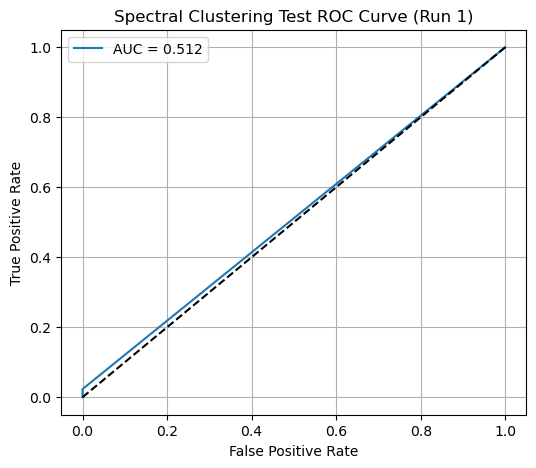

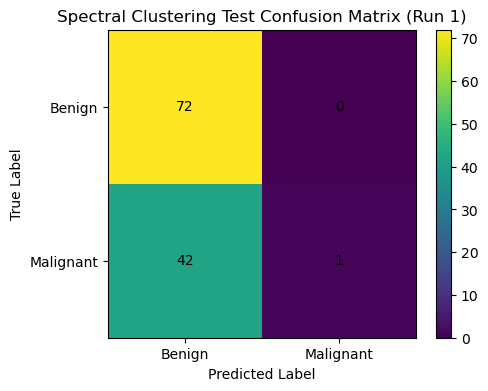

In [91]:
spectral_test_results = []
spectral_test_run1 = None
for run in range(M):
    X_train = semi_runs[run]['X_train']
    y_train = semi_runs[run]['y_train']
    X_test = semi_runs[run]['X_test']
    y_test = semi_runs[run]['y_test']
    #standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    #spectral clustering using RBF kernel
    model = SpectralClustering(
        n_clusters=2,
        affinity='rbf',
        gamma=1,
        assign_labels='kmeans',
        n_init=50,
        random_state=run
    )
    train_clusters = model.fit_predict(X_train_scaled)
    #assign true labels to clusters using majority vote
    cluster_labels = {}
    for cluster in range(2):
        members = np.where(train_clusters == cluster)[0]
        cluster_labels[cluster] = y_train.iloc[members].mode()[0]
    # assign test observations to the nearest training observation
    knn = KNeighborsClassifier(n_neighbors=1)
    knn.fit(X_train_scaled, train_clusters)
    test_clusters = knn.predict(X_test_scaled)
    # Convert predicted test clusters to diagnosis labels
    y_test_pred = np.array([cluster_labels[c] for c in test_clusters])
    y_test_score = y_test_pred
    # Evaluate test performance
    spectral_test_results.append({
        'Run': run + 1,
        'Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred, zero_division=0),
        'Recall': recall_score(y_test, y_test_pred, zero_division=0),
        'F1': f1_score(y_test, y_test_pred, zero_division=0),
        'AUC': roc_auc_score(y_test, y_test_score)
    })
    if run == 0:
        spectral_test_run1 = (y_test, y_test_pred, y_test_score)
#average test metrics over 30 runs
spectral_test_df = pd.DataFrame(spectral_test_results)
spectral_test_avg = spectral_test_df[
    ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
].mean()
print("Average Spectral Clustering Test Performance:")
print(spectral_test_avg.round(4))
#ROC curve for Run 1
y_test, y_test_pred, y_test_score = spectral_test_run1
fpr, tpr, _ = roc_curve(y_test, y_test_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_test_score):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Spectral Clustering Test ROC Curve (Run 1)')
plt.legend()
plt.grid()
plt.show()
#confusion matrix for Run 1
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Spectral Clustering Test Confusion Matrix (Run 1)')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

#### (iv) Compare

In [92]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
comparison = pd.DataFrame({
    'Supervised SVM': avg_scores.loc['Test', metrics],
    'Semi-Supervised SVM': semi_B_df[semi_B_df['Set'] == 'Test'][metrics].mean(),
    'K-means': kmeans_test_df[metrics].mean(),
    'Spectral Clustering': spectral_test_df[metrics].mean()
})
print("Average Test Performance Comparison:")
print(comparison.round(4))

Average Test Performance Comparison:
           Supervised SVM  Semi-Supervised SVM  K-means  Spectral Clustering
Accuracy           0.9739               0.9664   0.9119               0.6287
Precision          0.9791               0.9737   0.9240               0.3000
Recall             0.9512               0.9364   0.8333               0.0070
F1                 0.9643               0.9542   0.8757               0.0136
AUC                0.9939               0.9915   0.8961               0.5035


## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [93]:
columns = ['Variance', 'Skewness', 'Curtosis', 'Entropy', 'Class']
df = pd.read_csv('../data/data_banknote_authentication.txt', header=None, names=columns)
X = df.drop(columns=['Class'])
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=472, random_state=42
)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (900, 4)
Test set: (472, 4)


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

   Training Size  Average Test Error
0             10            0.133305
1             20            0.053686
2             30            0.042966
3             40            0.031695
4             50            0.028220


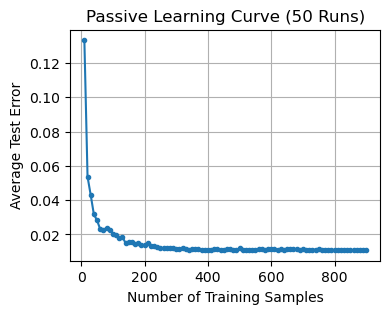

In [94]:
M = 50
pool_sizes = range(10, 901, 10)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
passive_errors = []

for run in range(M):
    #randomly shuffle each class separately
    class0 = np.random.permutation(np.where(y_train == 0)[0])
    class1 = np.random.permutation(np.where(y_train == 1)[0])

    #start with 5 samples from each class, then randomly mix the rest
    first10 = np.concatenate([class0[:5], class1[:5]])
    remaining = np.random.permutation(np.concatenate([class0[5:], class1[5:]]))
    order = np.concatenate([np.random.permutation(first10), remaining])

    run_errors = []

    for size in pool_sizes:
        idx = order[:size]
        X_pool = X_train.iloc[idx]
        y_pool = y_train.iloc[idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000))
        ])

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run)

        grid = GridSearchCV(
            pipeline,
            {'svm__C': C_values},
            cv=cv,
            scoring='accuracy'
        )
        grid.fit(X_pool, y_pool)
        y_test_pred = grid.predict(X_test)
        run_errors.append(1 - accuracy_score(y_test, y_test_pred))
    passive_errors.append(run_errors)
    #print(f"Run {run + 1}/{M} completed")
# Average test errors
passive_errors = np.array(passive_errors)
passive_avg_error = passive_errors.mean(axis=0)
passive_df = pd.DataFrame({
    'Training Size': list(pool_sizes),
    'Average Test Error': passive_avg_error
})

print(passive_df.head())
#plot passive learning curve
plt.figure(figsize=(4, 3))
plt.plot(list(pool_sizes), passive_avg_error, marker='o', markersize=3)
plt.xlabel('Number of Training Samples')
plt.ylabel('Average Test Error')
plt.title('Passive Learning Curve (50 Runs)')
plt.grid()
plt.show()

#### (ii) Active

   Training Size  Average Test Error
0             10            0.120763
1             20            0.050932
2             30            0.029407
3             40            0.022161
4             50            0.017034


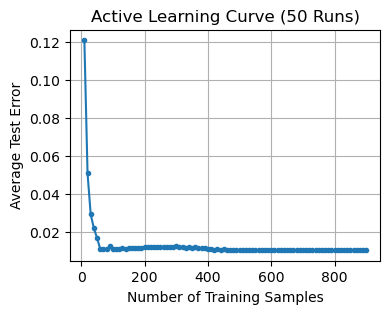

In [95]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
M = 50
pool_sizes = range(10, 901, 10)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
active_errors = []
for run in range(M):
    class0 = np.random.permutation(np.where(y_train.to_numpy() == 0)[0])
    class1 = np.random.permutation(np.where(y_train.to_numpy() == 1)[0])
    pool_idx = np.concatenate([class0[:5], class1[:5]])
    pool_idx = np.random.permutation(pool_idx)
    remaining_idx = np.setdiff1d(np.arange(len(X_train)), pool_idx)
    run_errors = []

    for size in pool_sizes:
        X_pool = X_train.iloc[pool_idx]
        y_pool = y_train.iloc[pool_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000, tol=0.01))
        ])
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run)
        grid = GridSearchCV(pipeline, {'svm__C': C_values}, cv=cv, scoring='accuracy')
        grid.fit(X_pool, y_pool)
        y_test_pred = grid.predict(X_test)
        run_errors.append(1 - accuracy_score(y_test, y_test_pred))
        if size < 900:
            scores = np.abs(grid.best_estimator_.decision_function(X_train.iloc[remaining_idx]))
            closest_idx = remaining_idx[np.argsort(scores)[:10]]
            pool_idx = np.concatenate([pool_idx, closest_idx])
            remaining_idx = np.setdiff1d(remaining_idx, closest_idx)

    active_errors.append(run_errors)
active_errors = np.array(active_errors)
active_avg_error = active_errors.mean(axis=0)
active_df = pd.DataFrame({
    'Training Size': list(pool_sizes),
    'Average Test Error': active_avg_error
})

print(active_df.head())
#plot
plt.figure(figsize=(4, 3))
plt.plot(list(pool_sizes), active_avg_error, marker='o', markersize=3)
plt.xlabel('Number of Training Samples')
plt.ylabel('Average Test Error')
plt.title('Active Learning Curve (50 Runs)')
plt.grid()
plt.show()

### (c) Average the 50 test errors

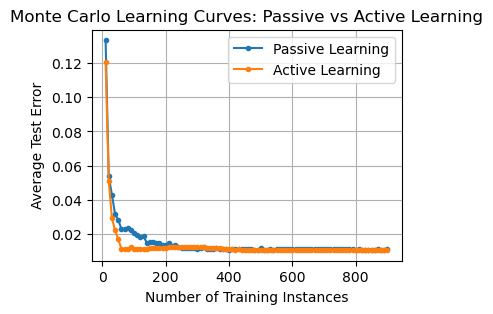

In [96]:
#test error over 50 runs for each training size
passive_avg_error = np.mean(passive_errors, axis=0)
active_avg_error = np.mean(active_errors, axis=0)

training_sizes = list(range(10, 901, 10))

#plot both learning curves
plt.figure(figsize=(4, 3))
plt.plot(training_sizes, passive_avg_error, label='Passive Learning', marker='o', markersize=3)
plt.plot(training_sizes, active_avg_error, label='Active Learning', marker='o', markersize=3)
plt.xlabel('Number of Training Instances')
plt.ylabel('Average Test Error')
plt.title('Monte Carlo Learning Curves: Passive vs Active Learning')
plt.legend()
plt.grid()
plt.show()